# Computing the Distance Grid

In this tutorial, one of the most useful and foundational calculations in mofography, the distance grid. The distance grid refers to a 3D array of floating point values, where the value in each voxel corresponds to the shortest distance to the nearest framework surface. Of course, the definition of framework surface requires assigning some radii to the atoms of the material. By default, mofography uses the covalent radii of the atoms, but you can also use the van der Waals radii or some other mixed and matched set of radii, as we will see shortly. So, in this tutorial we will see the following:

- How to compute the distance grid
- What are the different options while computing the distance grid
- How to visualize the distance grid
  - Computing a distance isosurface
- How to overlay it with the structure visualization from the earlier tutorial. 
- Where to go next

The first few steps are same as before, so we won't be explaining them in detail here, please refer to the Basic structure IO tutorial for more details.


## Imports and paths

In [1]:
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)

import mofography as mgr

path_to_cif = os.path.join(path_to_mgr, 'examples',
                           'TestCIFs', 'P1-IRMOF-1.cif')


## Read in a structure

In [2]:
from ase.io import read 
mat_atoms = read(path_to_cif)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\io\cif.py:401: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Computing the distance grid
The most important parameter in computing the grid is the grid spacing. This is the fineness of your grid, and is input as the distance between adjacent voxels in angstroms. The finer the grid, the more accurate the calculations, although, keep in mind that,
- when you reduce the grid spacing by a factor of 2, the number of voxels in the grid increases by a factor of 8.
- all the subsequent calculations would also be more expensive, since the grid is larger.

### Calculation under the hood
- On a CPU:
mofography uses Dask to paralellize the grid calcuation for efficiency. Hence, the returned object is a Dask array, which can be converted to a numpy array using the `compute()` method. On top of that, mofography borrows the AABB cell list algorithm from Freud, to further speed up the calculation manifold. 

Some information about the function

In [3]:
help(mgr.dgrid_from_atoms)

Help on function dgrid_from_atoms in module mofography.compute:

dgrid_from_atoms(ase_atoms, radii=None, spacing=0.25, block_size=50000, n_neighbors=10, probe_radius=0)
    The function `dgrid_from_atoms` generates a distance grid over atoms using Dask arrays and computes
    the grid based on atomic radii and specified parameters.
    
    :param ase_atoms: The `ase_atoms` parameter in the `dgrid_from_atoms` function is expected to be an
    ASE Atoms object, which represents a collection of atoms and their properties. This object typically
    contains information about the atomic positions, chemical symbols, and unit cell of a molecular
    system. You can create an
    :param radii: The `radii` parameter in the `dgrid_from_atoms` function is used to specify the atomic
    radii for the atoms in the input `ase_atoms`. If the `radii` parameter is not provided by the user,
    a default set of van der Waals radii for different elements
    :param spacing: The `spacing` parameter in th

Let's compute a 0.25 $\AA$ grid for IRMOF-1

In [4]:
dgrid = mgr.dgrid_from_atoms(mat_atoms, spacing=0.25)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)
Computing distance grid: 100%|██████████| 23/23 [00:04<00:00,  4.66it/s]


Let's look at this returned grid

In [5]:
dgrid

dask.array<reshape, shape=(104, 104, 104), dtype=float64, chunksize=(5, 104, 104), chunktype=numpy.ndarray>

as I was mentioning earlier, this is a Dask array, so we can convert it to a numpy array using the `compute()` method

In [6]:
dgrid.compute()

array([[[7.53790836, 7.34081154, 7.14643459, ..., 7.14643459,
         7.34081154, 7.53790836],
        [7.34081154, 7.18741684, 6.98960953, ..., 6.98960857,
         7.18741589, 7.34081154],
        [7.14643459, 6.98960953, 6.8372715 , ..., 6.8372715 ,
         6.98960953, 7.14643459],
        ...,
        [7.14643459, 6.98960953, 6.8372715 , ..., 6.8372715 ,
         6.98960857, 7.14643459],
        [7.34081059, 7.18741589, 6.98960857, ..., 6.98960857,
         7.18741589, 7.34081059],
        [7.53790836, 7.34081154, 7.14643459, ..., 7.14643459,
         7.34081154, 7.53790836]],

       [[7.34081154, 7.18741684, 6.98960953, ..., 6.98960857,
         7.18741589, 7.34081154],
        [7.18741684, 7.15189247, 6.97315674, ..., 6.97315674,
         7.15189152, 7.18741684],
        [6.98960857, 6.97315674, 6.80028419, ..., 6.80028419,
         6.97315674, 6.98960857],
        ...,
        [6.98960857, 6.97315674, 6.80028419, ..., 6.80028324,
         6.97315674, 6.98960857],
        [7.1

### Tips and tricks #1
In parallel computing, it is pivotal to divide the calculation into pieces of the right size. If the pieces are too small, the overhead of the parallelization is too high, and if the pieces are too large, the parallelization is not effective. The `chunk_size` parameter in the `compute()` method allows you to specify the size of the chunks. The default value is 50000 which is a good starting point. If you are running into memory issues, you can reduce this value. If your RAM is not being fully utilized, you can increase this value, if your RAM is too small, you may want to reduce this value.

### Tips and tricks #2
By default, mofography uses a point probe, meaning it has no size. If you'd like a different probe, like argon, you can specify it using the `probe_radius` parameter. We will leave that as an exercise.

### Tips and tricks #3
If you have a lot of atoms in your unit cell, you may want to reduce the n_neighbors parameter, it will make the calculation of the AABB cell list faster. The default value is 10, which is a good starting point. Since we want the probe-to-framework, surface-to-surface distance, and not the center-to-center distance, we should consider a few center-to-center neighbors while checking for the one with the shortest surface-to-surface distance.

- On a GPU (+CPU):
If you have a powerful nvidia GPU, we might be able to take advantage of that to speed up the calculation. The GPU routine is quite similar to the CPU routine, but doesn't use the cell list algorithm, for memory management reasons. Essentially, it breaks down the calculation onto different cores of the CPU, and then each core talks to the GPU independently to do the calculation. It uses a CuPy backend to do the calculations on the GPU. Unlike the CPU version, it returns a CuPy array. You can convert it to a numpy array using the `asnumpy()` function. Still, you might get a speed up over the CPU routine. Let's look at it in action


In [7]:
help(mgr.dgrid_from_atoms_gpu)


Help on function dgrid_from_atoms_gpu in module mofography.compute:

dgrid_from_atoms_gpu(ase_atoms, radii=None, spacing=0.2, block_size=10000)
    The function `dgrid_from_atoms_gpu` calculates a distance grid based on atomic positions using GPU
    acceleration.
    
    :param ase_atoms: The `ase_atoms` parameter in the `dgrid_from_atoms_gpu` function is expected to be
    an ASE Atoms object, which represents a collection of atoms and their properties. This object
    typically contains information such as atomic positions, unit cell parameters, atomic symbols, and
    other properties of the atoms in
    :param radii: The `radii` parameter in the `dgrid_from_atoms_gpu` function represents the van der
    Waals radii of the atoms in the atomic structure provided as input. These radii are used in the
    calculation of the distance grid. If the `radii` parameter is not provided by the
    :param spacing: The `spacing` parameter in the `dgrid_from_atoms_gpu` function represents the
 

In [8]:
dgrid_gpu = mgr.dgrid_from_atoms_gpu(mat_atoms, spacing=0.25)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)


Output()

In [9]:
dgrid_gpu.device

<CUDA Device 0>

In [10]:
import cupy as cp
cp.asnumpy(dgrid_gpu)

array([[[7.53790858, 7.34081198, 7.1464346 , ..., 7.1464346 ,
         7.34081198, 7.53790858],
        [7.34081198, 7.18741734, 6.98960936, ..., 6.98960936,
         7.18741734, 7.34081198],
        [7.1464346 , 6.98960936, 6.83727204, ..., 6.83727204,
         6.98960936, 7.1464346 ],
        ...,
        [7.1464346 , 6.98960936, 6.83727204, ..., 6.83727204,
         6.98960936, 7.1464346 ],
        [7.34081198, 7.18741734, 6.98960936, ..., 6.98960936,
         7.18741734, 7.34081198],
        [7.53790858, 7.34081198, 7.1464346 , ..., 7.1464346 ,
         7.34081198, 7.53790858]],

       [[7.34081198, 7.18741734, 6.98960936, ..., 6.98960936,
         7.18741734, 7.34081198],
        [7.18741734, 7.15189259, 6.9731576 , ..., 6.9731576 ,
         7.15189259, 7.18741734],
        [6.98960936, 6.9731576 , 6.80028407, ..., 6.80028407,
         6.9731576 , 6.98960936],
        ...,
        [6.98960936, 6.9731576 , 6.80028407, ..., 6.80028407,
         6.9731576 , 6.98960936],
        [7.1

### Tips and tricks #4

All the CPU cores need to be able to talk to the GPU at the same time, if your GPU memory is low, this might result in a segmentation fault. But, not to worry, simply reduce the 'block_size' parameter and you should be good to go. Not that, as before, making the block size too small could result in computational bottlenecks in memory instead of the actual computation, resulting in worse performance.

## Visualizing the distance grid

Usually plotting a 3D volume is computationally expensive and often unclear. Instead, we can plot and isosurface of the distance grid, which is a surface that is at a certain constant distance from the framework surface. This is a much more intuitive way to visualize the distance grid. Let's look at how to do that in mofography.



### A note on the renderer

In Plotly you can have many different renderers, in this tutorial we are using `renderer='png'` to save some space by rendering as a static image. Instead to get an interactive plot, you can use `renderer='notebook_connected'` or `renderer='browser'` to get an interactive plot in the notebook or in a separate browser tab respectively.

In [11]:
help(mgr.plot_surface_dgrid)

Help on function plot_surface_dgrid in module mofography.visualize:

plot_surface_dgrid(dgrid, isovalue, ase_atoms, region_labels=None, select='all', opacity=1.0, cscale=None, color='blue', stepsize=1, stylize=False, random_seed=0, hover_label='Region :', **kwargs_mesh)
    It takes a 3D grid, an isovalue, an ASE atoms object, and a few other optional parameters and
    returns a plotly mesh3d object that can be plotted using plotly
    
    Args:
      dgrid: the density grid
      isovalue: the value of the isosurface to be plotted
      ase_atoms: ASE atoms object
      region_labels: a 3D array of the same shape as the density grid. Each voxel in the density grid is
    assigned a label. The labels are used to color the surface.
      select: a list of region labels to plot. If 'all' is selected, all regions are plotted. Defaults
    to all
      opacity: The opacity of the surface.
      cscale: a colorscale for the regions. If None, a random colorscale is generated.
      color: 

let's plot an isosurface at 2.5 $\AA$ from the framework surface

In [12]:
isosurface_trace = mgr.plot_surface_dgrid(cp.asnumpy(dgrid_gpu), ase_atoms = mat_atoms , isovalue=2.5, color='turquoise', opacity=0.6)
isosurface_trace

Mesh3d({
    'color': 'turquoise',
    'hoverinfo': 'all',
    'i': array([    2,     2,     0, ..., 71975, 71259, 71259]),
    'j': array([    1,     0,     5, ..., 71974, 71243, 71962]),
    'k': array([    0,     3,     4, ..., 71258, 71962, 71975]),
    'name': '2.5 A isosurface',
    'opacity': 0.6,
    'showlegend': True,
    'x': array([ 0.        ,  0.24838462,  0.24838462, ..., 25.58361538, 25.58361538,
                25.58361538]),
    'y': array([ 1.48645795,  1.45218431,  1.49030769, ..., 24.13153223, 24.12191687,
                24.09715649]),
    'z': array([ 6.70638462,  6.70638462,  6.46868083, ..., 18.38046154, 18.62884615,
                18.87723077])
})

Let's make a plolty figure, and add the isosurface and the structure to it. Please refer to the earlier tutorial if you are unsure about how to visualize the structure in mofography

In [13]:
import plotly.graph_objects as go
fig = go.Figure(data=[isosurface_trace, mgr.plot_cell(mat_updated), *mgr.plot_framework_as_mesh(mat_updated)]).update(layout=mgr.dark_layout)


c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:814: UserWarning: Optimal rotation is not uniquely or poorly defined for the given sets of vectors.
  r = R.align_vectors(ring_normal.reshape(-1, 3), np.array([0, 0, 1]).reshape(-1, 3))


Note: Don't forget teh `*` infront of the framework trace to unpack the list of traces into the figure.

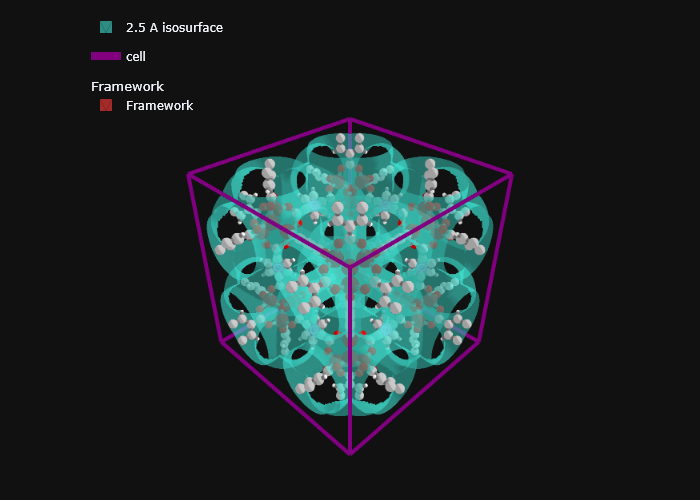

In [14]:
fig.show(renderer='png')

### Tips and tricks #5

Use the stylize flag to stylize the framework and isosurface plot using a default set of lighting options.

In [15]:
isosurface_trace = mgr.plot_surface_dgrid(cp.asnumpy(dgrid_gpu), ase_atoms = mat_atoms , isovalue=2.5, color='turquoise', opacity=0.6, stylize=True)
frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
cell_trace = mgr.plot_cell(mat_updated)
fig = go.Figure(data=[isosurface_trace, cell_trace, *frame_trace]).update(layout=mgr.dark_layout)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:814: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



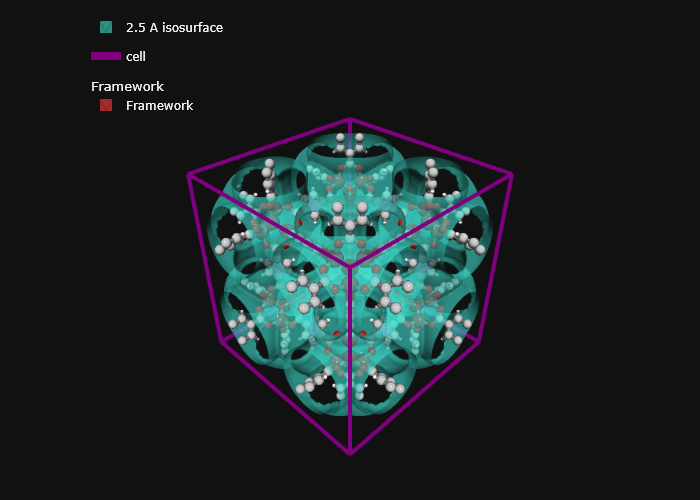

In [16]:
fig.show(renderer='png')

### Tips and tricks #6

Use the `stepsize` parameter to plot a coarser surface. If you have a really fine grid, or a really large unit cell, or you simply want to plot the surface quickly, you might want to plot a coarser isosurface. For example, set `stepsize=2` to plot every other vertex in the isosurface.

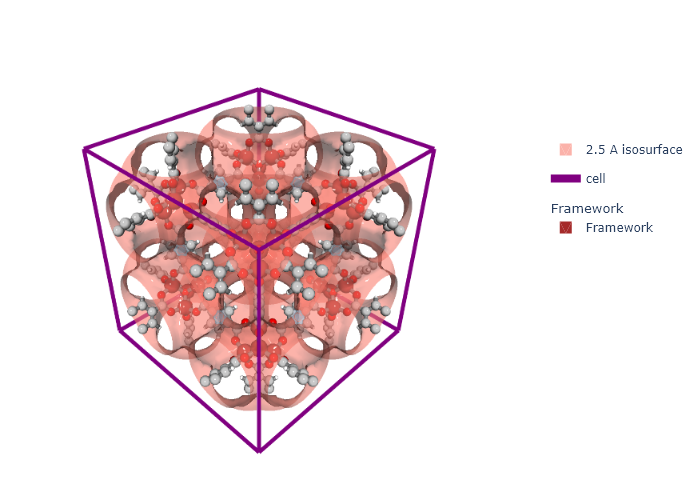

In [17]:
isosurface_trace = mgr.plot_surface_dgrid(cp.asnumpy(dgrid_gpu), stepsize=2, ase_atoms = mat_atoms , isovalue=2.5, color='salmon', opacity=0.6, stylize=True)
fig = go.Figure(data=[isosurface_trace, cell_trace, *frame_trace]).update(layout=mgr.white_layout)
fig.show(renderer='png')